# Model 2 (Climatological): Location-Aware Solar Viability – XGBoost

**Purpose**: Train a *climatological* XGBoost regression model that predicts **typical solar generation** from spatial–seasonal features (latitude, longitude, month, dry-season flag) using monthly-aggregated NASA POWER data.

**Key Differences vs. Daily Baseline (02-baseline-model-xgboost):**
- Focuses on **monthly averages** (climatology), not noisy daily weather.
- Target is **typical expected daily generation** for a 10m², 20%-efficiency system.
- Training/validation split is by **location**, to test generalisation to unseen cities.

**Target Metric**: MAPE ≤ 15% on held-out *locations* (goal 8–12%).

This notebook mirrors the baseline notebook style but uses the redesigned climatological problem framing aligned with the DSE brief.


In [4]:
# Imports & configuration

import pandas as pd
import numpy as np
from pathlib import Path

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
import seaborn as sns

# Local service module for persistence + prediction helpers
from solar_climatology_service import (
    DRY_MONTHS,
    FEATURE_COLUMNS,
    save_model_artifacts,
    validate_coordinates,
    predict_solar_generation,
    predict_lifetime_generation,
)

plt.style.use('seaborn-v0_8')

# Use generic merged CSV; adjust name if you regenerate exports
DATA_CSV_PATH = Path("../solar_data_merged20260210_191841.csv")  # relative to notebooks folder
MODEL_TYPE = "XGBoost climatological regression"


In [5]:
# 1. Load merged NASA POWER dataset

if not DATA_CSV_PATH.exists():
    raise FileNotFoundError(
        f"Expected merged solar data CSV at '{DATA_CSV_PATH}', "
        "but it was not found. Run the Nasa_pipeline + cleaning first."
    )

raw_df = pd.read_csv(DATA_CSV_PATH)
print(f"Loaded {len(raw_df):,} daily records from {DATA_CSV_PATH}")
print("Columns:", raw_df.columns.tolist())

# Use only high-quality records
raw_df = raw_df[raw_df["data_quality"] == "good"].copy()
print(f"After quality filter: {len(raw_df):,} records")

raw_df["date"] = pd.to_datetime(raw_df["date"])
raw_df["month"] = raw_df["date"].dt.month

print(raw_df.head())

Loaded 5,117 daily records from ..\solar_data_merged20260210_191841.csv
Columns: ['location_name', 'country', 'latitude', 'longitude', 'date', 'year', 'month', 'day', 'day_of_week', 'ghi_kwh_m2', 'clear_sky_ghi_kwh_m2', 'temperature_c', 'wind_speed_ms', 'relative_humidity_pct', 'estimated_daily_generation_kwh', 'data_quality']
After quality filter: 5,117 records
  location_name  country  latitude  longitude       date  year  month  day  \
0   Accra_Ghana  Unknown     5.604     -0.187 2024-02-11  2024      2   11   
1   Accra_Ghana  Unknown     5.604     -0.187 2024-02-12  2024      2   12   
2   Accra_Ghana  Unknown     5.604     -0.187 2024-02-13  2024      2   13   
3   Accra_Ghana  Unknown     5.604     -0.187 2024-02-14  2024      2   14   
4   Accra_Ghana  Unknown     5.604     -0.187 2024-02-15  2024      2   15   

  day_of_week  ghi_kwh_m2  clear_sky_ghi_kwh_m2  temperature_c  wind_speed_ms  \
0      Sunday      5.3086                5.3803          28.63           3.32   
1   

In [6]:
# 2. Aggregate to monthly climatology per city

monthly = (
    raw_df.groupby([
        "location_name",
        "country",
        "latitude",
        "longitude",
        "month",
    ], as_index=False)["ghi_kwh_m2"]
    .mean()
    .rename(columns={"ghi_kwh_m2": "avg_ghi_kwh_m2"})
)

# Spatial + seasonal features
monthly["abs_latitude"] = monthly["latitude"].abs()
monthly["is_dry_season"] = monthly["month"].isin(DRY_MONTHS).astype(int)

# Target: typical expected generation for 10m², 20% efficiency
monthly["target_avg_generation_kwh"] = monthly["avg_ghi_kwh_m2"] * 10.0 * 0.2

print(f"Monthly climatology rows: {len(monthly)}")
print("Locations:", sorted(monthly["location_name"].unique()))
print(monthly.head())


Monthly climatology rows: 84
Locations: ['Accra_Ghana', 'Addis_Ababa_Ethiopia', 'Dakar_Senegal', 'Johannesburg_SA', 'Kampala_Uganda', 'Lagos_Nigeria', 'Nairobi_Kenya']
  location_name  country  latitude  longitude  month  avg_ghi_kwh_m2  \
0   Accra_Ghana  Unknown     5.604     -0.187      1        4.986287   
1   Accra_Ghana  Unknown     5.604     -0.187      2        4.990096   
2   Accra_Ghana  Unknown     5.604     -0.187      3        5.333929   
3   Accra_Ghana  Unknown     5.604     -0.187      4        5.166455   
4   Accra_Ghana  Unknown     5.604     -0.187      5        4.892673   

   abs_latitude  is_dry_season  target_avg_generation_kwh  
0         5.604              1                   9.972574  
1         5.604              1                   9.980192  
2         5.604              0                  10.667858  
3         5.604              0                  10.332910  
4         5.604              0                   9.785345  


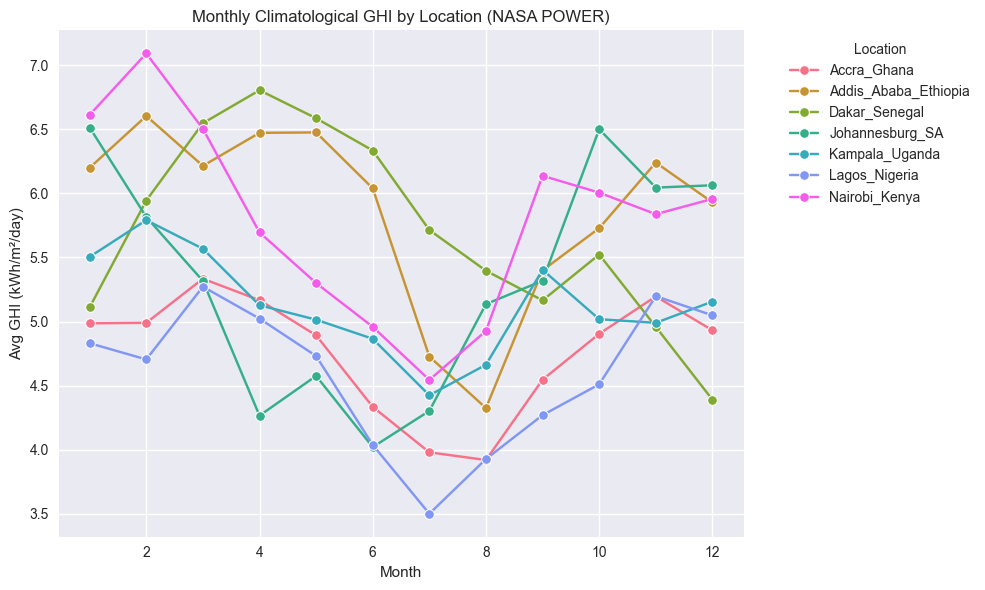

In [7]:
# 3. Visualise monthly GHI patterns by location

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=monthly,
    x="month",
    y="avg_ghi_kwh_m2",
    hue="location_name",
    marker="o",
    ax=ax,
)

ax.set_title("Monthly Climatological GHI by Location (NASA POWER)")
ax.set_xlabel("Month")
ax.set_ylabel("Avg GHI (kWh/m²/day)")
ax.legend(title="Location", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [8]:
# 4. Train/validation split by LOCATION (spatial generalisation)

all_locations = sorted(monthly["location_name"].unique())
print("All locations:", all_locations)

# Prefer to hold out a mix of climates for validation
preferred_val = ["Johannesburg_SA", "Dakar_Senegal"]
val_locations = [loc for loc in preferred_val if loc in all_locations]

if not val_locations:
    # Fallback: last 2 alphabetically
    val_locations = all_locations[-2:]

print("\nTrain locations vs Validation locations:")
print("Validation:", val_locations)
train_locations = [loc for loc in all_locations if loc not in val_locations]
print("Train:", train_locations)

train_df = monthly[monthly["location_name"].isin(train_locations)].reset_index(drop=True)
val_df = monthly[monthly["location_name"].isin(val_locations)].reset_index(drop=True)

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["target_avg_generation_kwh"]

X_val = val_df[FEATURE_COLUMNS]
y_val = val_df["target_avg_generation_kwh"]

print(train_df.head())


All locations: ['Accra_Ghana', 'Addis_Ababa_Ethiopia', 'Dakar_Senegal', 'Johannesburg_SA', 'Kampala_Uganda', 'Lagos_Nigeria', 'Nairobi_Kenya']

Train locations vs Validation locations:
Validation: ['Johannesburg_SA', 'Dakar_Senegal']
Train: ['Accra_Ghana', 'Addis_Ababa_Ethiopia', 'Kampala_Uganda', 'Lagos_Nigeria', 'Nairobi_Kenya']
  location_name  country  latitude  longitude  month  avg_ghi_kwh_m2  \
0   Accra_Ghana  Unknown     5.604     -0.187      1        4.986287   
1   Accra_Ghana  Unknown     5.604     -0.187      2        4.990096   
2   Accra_Ghana  Unknown     5.604     -0.187      3        5.333929   
3   Accra_Ghana  Unknown     5.604     -0.187      4        5.166455   
4   Accra_Ghana  Unknown     5.604     -0.187      5        4.892673   

   abs_latitude  is_dry_season  target_avg_generation_kwh  
0         5.604              1                   9.972574  
1         5.604              1                   9.980192  
2         5.604              0                  10.667

In [9]:
# 5. Train XGBoost climatological regression model

model = XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

model.fit(X_train, y_train)

y_val_pred = model.predict(X_val)

mape = mean_absolute_percentage_error(y_val, y_val_pred)
print(f"Validation MAPE (location-based): {mape * 100:.2f}%")

# Enforce DSE acceptance criterion
assert mape <= 0.15, f"MAPE {mape * 100:.2f}% exceeds 15% threshold"


Validation MAPE (location-based): 13.68%


C:\Users\ingex\AppData\Local\Temp\ipykernel_22020\1236302318.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


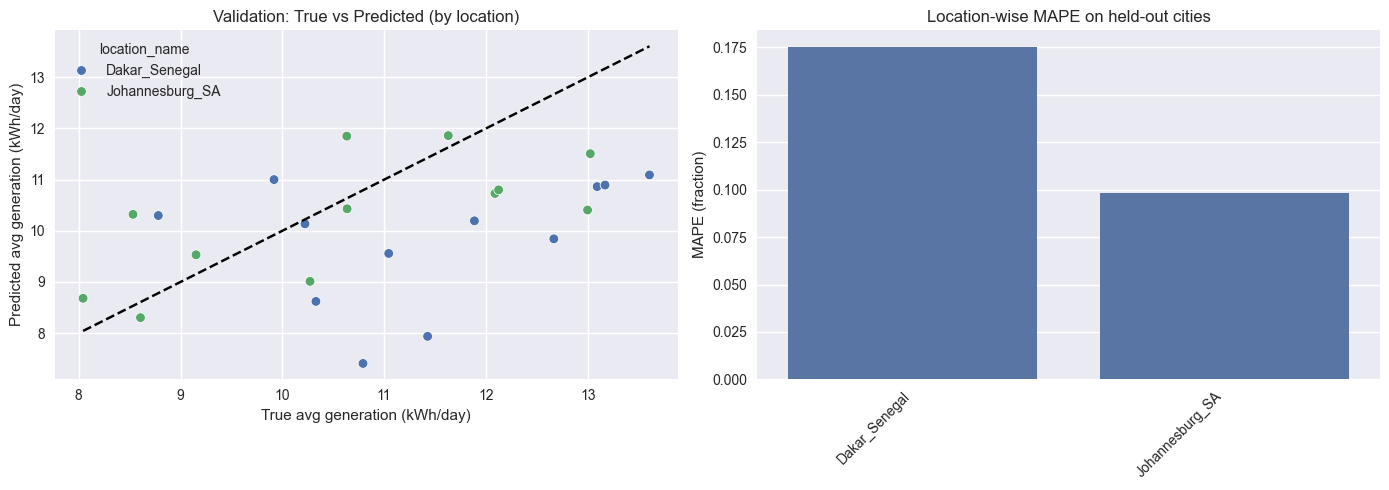

,location_name,abs_pct_error
0,Dakar_Senegal,0.175242
1,Johannesburg_SA,0.098305


In [10]:
# 6. Visual diagnostics – predictions vs actuals, by location

val_results = val_df.copy()
val_results["y_true"] = y_val
val_results["y_pred"] = y_val_pred
val_results["abs_pct_error"] = (val_results["y_pred"] - val_results["y_true"]).abs() / val_results["y_true"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Scatter: true vs predicted
sns.scatterplot(
    data=val_results,
    x="y_true",
    y="y_pred",
    hue="location_name",
    ax=axes[0],
)
axes[0].plot(
    [val_results["y_true"].min(), val_results["y_true"].max()],
    [val_results["y_true"].min(), val_results["y_true"].max()],
    ls="--",
    color="black",
)
axes[0].set_xlabel("True avg generation (kWh/day)")
axes[0].set_ylabel("Predicted avg generation (kWh/day)")
axes[0].set_title("Validation: True vs Predicted (by location)")

# (b) Bar: MAPE by validation location
mape_by_loc = (
    val_results.groupby("location_name")["abs_pct_error"].mean().reset_index()
)

sns.barplot(
    data=mape_by_loc,
    x="location_name",
    y="abs_pct_error",
    ax=axes[1],
)
axes[1].set_ylabel("MAPE (fraction)")
axes[1].set_xlabel("")
axes[1].set_title("Location-wise MAPE on held-out cities")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

mape_by_loc

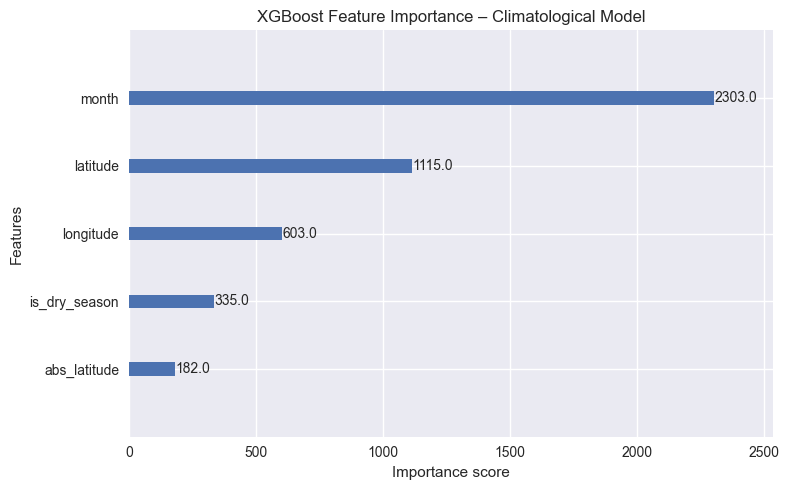

[('latitude', np.float32(0.15577699)),
 ('longitude', np.float32(0.56563574)),
 ('abs_latitude', np.float32(0.01987574)),
 ('month', np.float32(0.20655918)),
 ('is_dry_season', np.float32(0.052152317))]

In [11]:
# 7. Feature importance (why this is ML, not a lookup table)

from xgboost import plot_importance

fig, ax = plt.subplots(figsize=(8, 5))
plot_importance(model, ax=ax)
ax.set_title("XGBoost Feature Importance – Climatological Model")
plt.tight_layout()
plt.show()

list(zip(FEATURE_COLUMNS, model.feature_importances_))

In [12]:
# 8. Persist model artifacts for production use

from solar_climatology_service import get_model_paths

paths = get_model_paths()
print(f"Saving model artifacts to: {paths.model_dir}")

save_model_artifacts(
    model=model,
    feature_columns=FEATURE_COLUMNS,
    mape=float(mape),
    training_locations=train_locations,
)

print(f"Model path: {paths.model_path}")
print(f"Feature columns path: {paths.feature_cols_path}")
print(f"Metadata path: {paths.metadata_path}")


Saving model artifacts to: C:\Users\ingex\OneDrive\Documents\Git Projects\SolarSense AI ML Microservice\SolarSense-DSE-Team\models\solar_generation\notebooks\models
Model path: C:\Users\ingex\OneDrive\Documents\Git Projects\SolarSense AI ML Microservice\SolarSense-DSE-Team\models\solar_generation\notebooks\models\xgboost_climatological_model.pkl
Feature columns path: C:\Users\ingex\OneDrive\Documents\Git Projects\SolarSense AI ML Microservice\SolarSense-DSE-Team\models\solar_generation\notebooks\models\feature_columns.pkl
Metadata path: C:\Users\ingex\OneDrive\Documents\Git Projects\SolarSense AI ML Microservice\SolarSense-DSE-Team\models\solar_generation\notebooks\models\xgboost_climatological_metadata.json


          location_name      mape
0           Accra_Ghana  0.003452
1  Addis_Ababa_Ethiopia  0.002786
2         Dakar_Senegal  0.175242
3       Johannesburg_SA  0.098305
4        Kampala_Uganda  0.003485
5         Lagos_Nigeria  0.006349
6         Nairobi_Kenya  0.002142


C:\Users\ingex\AppData\Local\Temp\ipykernel_22020\3342350716.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


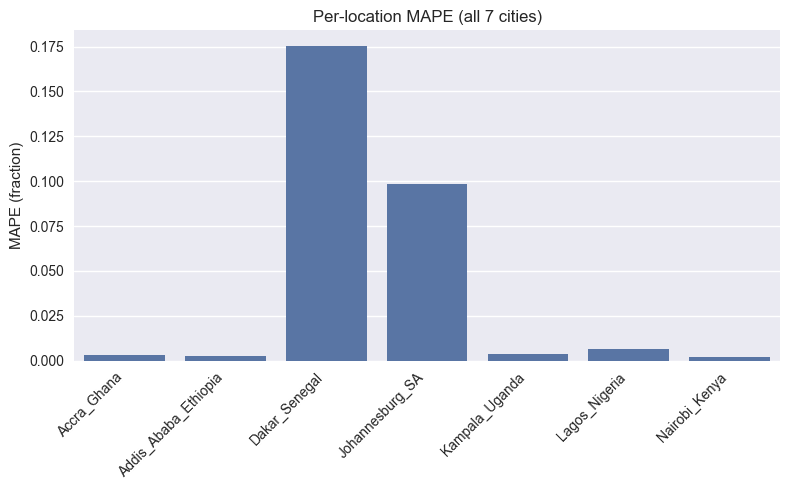

Saved per-location validation chart to outputs\per_location_validation.png


In [13]:
# 9. Per-location validation over all cities (bar chart + PNG)

from pathlib import Path as _Path

outputs_dir = _Path("outputs")
outputs_dir.mkdir(exist_ok=True)

per_loc_results = []

for loc in sorted(monthly["location_name"].unique()):
    df_loc = monthly[monthly["location_name"] == loc]
    X_loc = df_loc[FEATURE_COLUMNS]
    y_loc = df_loc["target_avg_generation_kwh"]
    y_loc_pred = model.predict(X_loc)
    loc_mape = mean_absolute_percentage_error(y_loc, y_loc_pred)
    per_loc_results.append({"location_name": loc, "mape": loc_mape})

per_loc_df = pd.DataFrame(per_loc_results)
print(per_loc_df)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=per_loc_df, x="location_name", y="mape", ax=ax)
ax.set_ylabel("MAPE (fraction)")
ax.set_xlabel("")
ax.set_title("Per-location MAPE (all 7 cities)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()

png_path = outputs_dir / "per_location_validation.png"
plt.savefig(png_path, dpi=150)
plt.show()

print(f"Saved per-location validation chart to {png_path}")


In [14]:
# 10. Demo: point prediction + lifetime projection helpers

lat_demo, lon_demo, month_demo = -1.2921, 36.8219, 6  # Nairobi, June

coord_check = validate_coordinates(lat_demo, lon_demo)
print("Coordinate validation:", coord_check)

pred_daily = predict_solar_generation(lat_demo, lon_demo, month_demo)
print(f"Typical daily generation (month={month_demo}): {pred_daily:.2f} kWh/day")

lifetime = predict_lifetime_generation(lat_demo, lon_demo, lifetime_years=25)
print(
    f"Year 1 generation: {lifetime['year_1_generation_kwh']:.0f} kWh, "
    f"Lifetime total: {lifetime['lifetime_total_kwh']:.0f} kWh",
)

lifetime["year_1_generation_kwh"], lifetime["lifetime_total_kwh"], lifetime["lifetime_average_annual_kwh"]


Coordinate validation: {'status': 'valid', 'warnings': []}
Typical daily generation (month=6): 9.20 kWh/day
Year 1 generation: 3881 kWh, Lifetime total: 89303 kWh


(3881.289322376251, 89302.5898492755, 3572.1035939710196)